# ITRI626 — Phase 2/3: Train & Compare Three Models
### Pothole severity classification — custom CNN vs EfficientNetV2-S vs ViT-B/16

This notebook trains **three models from three different families on the *same* split**
produced by the Phase-1 data-prep notebook, and compares them fairly.

- **Model 1 — SmallCNN**: a compact custom convolutional network, trained **from scratch** (baseline).
- **Model 2 — EfficientNetV2-S**: fine-tuned from **ImageNet** weights (transfer learning).
- **Model 3 — ViT-B/16**: a Vision Transformer, fine-tuned from **ImageNet** weights (transfer learning).

It reports everything the brief requires: accuracy, per-class & macro precision/recall/F1,
confusion matrices, and training/validation curves — plus a side-by-side comparison table and
a correct/incorrect prediction gallery.

**Before running:** you need the `patches_dataset/` folder from Phase 1. Easiest options on Kaggle:
1. Run this in the **same notebook** right after the Phase-1 cells (it's already in `/kaggle/working`), **or**
2. **Save Version** of the Phase-1 notebook, then add its output as **input** to this notebook, **or**
3. Zip `patches_dataset/` into a new Kaggle Dataset and add it as input.

Turn on the **GPU** accelerator (Settings → Accelerator → GPU T4/P100).


In [1]:
# --- Dependencies ------------------------------------------------------------
import importlib, subprocess, sys
for pkg in ["torch", "torchvision", "timm", "scikit-learn", "pandas", "matplotlib", "seaborn"]:
    name = {"scikit-learn":"sklearn"}.get(pkg, pkg)
    try: importlib.import_module(name)
    except ImportError: subprocess.run([sys.executable,"-m","pip","install","-q",pkg], check=True)
import torch
print("torch", torch.__version__, "| CUDA available:", torch.cuda.is_available())

torch 2.11.0+cu128 | CUDA available: True


In [2]:
# --- Configuration -----------------------------------------------------------
from pathlib import Path
import torch

SEED       = 42
IMG_SIZE   = 224
NUM_WORKERS = 2
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
CLASSES = ["minor_pothole", "medium_pothole", "major_pothole"]

# Per-model hyperparameters. Pretrained models use a lower LR and fewer epochs than the
# from-scratch CNN; this is justified because fine-tuning adapts existing features while the
# custom CNN must learn everything. All three share the same data, split, loss and metrics.
MODEL_CFGS = {
    "SmallCNN":         dict(timm_name=None,                  pretrained=False, lr=1e-3, epochs=40, batch=32, weight_decay=1e-4),
    "EfficientNetV2-S": dict(timm_name="tf_efficientnetv2_s", pretrained=True,  lr=3e-4, epochs=20, batch=32, weight_decay=1e-4),
    "ViT-B/16":         dict(timm_name="vit_base_patch16_224",pretrained=True,  lr=1e-4, epochs=20, batch=32, weight_decay=5e-2),
}
EARLY_STOP_PATIENCE = 12      # stop if val macro-F1 doesn't improve for this many epochs
MIN_EPOCHS = 15
# --- Locate the Phase-1 output -----------------------------------------------
def find_patches():
    for root in ["/kaggle/working", ".", "/content", "/kaggle/input"]:
        rp = Path(root)
        if not rp.exists(): continue
        for p in [rp/"patches_dataset"] + list(rp.rglob("patches_dataset")):
            if (p/"train").is_dir() and (p/"test").is_dir():
                return p
    return None
DATA = find_patches()
if DATA is None:
    raise FileNotFoundError("Couldn't find patches_dataset/. Run Phase 1 first or add it as input.")
OUT = Path("/kaggle/working/models_out") if Path("/kaggle/working").exists() else Path("models_out")
OUT.mkdir(parents=True, exist_ok=True)
(OUT/"figures").mkdir(exist_ok=True); (OUT/"weights").mkdir(exist_ok=True)
print("DATA:", DATA, "| DEVICE:", DEVICE)

DATA: /kaggle/input/notebooks/owethusithole/itri626-phase1-dataprep/patches_dataset | DEVICE: cuda


In [3]:
# --- Reproducibility ---------------------------------------------------------
import random, numpy as np, torch
def seed_everything(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
seed_everything(SEED)
g = torch.Generator(); g.manual_seed(SEED)

## 1. Data loaders, preprocessing & augmentation

Preprocessing matches what the pretrained models expect (resize to 224, ImageNet mean/std).
**Augmentation is applied to the training set only** — mild geometric and photometric transforms
that are realistic for road photos (a pothole is still the same severity if flipped, slightly
rotated, or shot in different light). We never use vertical flips (roads have a fixed up/down)
or heavy crops (they could cut the pothole out).

In [4]:
import torchvision.transforms as T
from torchvision.datasets import ImageFolder
from torch.utils.data import DataLoader

IMAGENET_MEAN = [0.485, 0.456, 0.406]; IMAGENET_STD = [0.229, 0.224, 0.225]
train_tf = T.Compose([
    T.Resize((IMG_SIZE, IMG_SIZE)),
    T.RandomHorizontalFlip(0.5),
    T.RandomRotation(12),
    T.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.1),
    T.ToTensor(), T.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])
eval_tf = T.Compose([
    T.Resize((IMG_SIZE, IMG_SIZE)),
    T.ToTensor(), T.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

# ImageFolder sorts classes alphabetically; enforce our severity order for consistent labels.
def make_ds(split, tf):
    ds = ImageFolder(str(DATA/split), transform=tf)
    # remap so index 0/1/2 = minor/medium/major regardless of alphabetical order
    want = {c:i for i,c in enumerate(CLASSES)}
    remap = {ds.class_to_idx[c]: want[c] for c in CLASSES}
    ds.samples = [(p, remap[y]) for p,y in ds.samples]
    ds.targets = [remap[y] for y in ds.targets]
    ds.classes = CLASSES; ds.class_to_idx = want
    return ds

train_ds = make_ds("train", train_tf)
val_ds   = make_ds("val",   eval_tf)
test_ds  = make_ds("test",  eval_tf)
print({s: len(d) for s,d in [("train",train_ds),("val",val_ds),("test",test_ds)]})

def make_loader(ds, batch, shuffle):
    return DataLoader(ds, batch_size=batch, shuffle=shuffle, num_workers=NUM_WORKERS,
                      pin_memory=(DEVICE.type=="cuda"), generator=g, drop_last=False)

{'train': 1034, 'val': 223, 'test': 221}


In [5]:
# --- Class weights (handle the ~2:1 imbalance) -------------------------------
import numpy as np, torch
counts = np.bincount([y for _,y in train_ds.samples], minlength=len(CLASSES))
class_weights = torch.tensor(counts.sum() / (len(CLASSES) * counts), dtype=torch.float32).to(DEVICE)
print("train class counts:", dict(zip(CLASSES, counts.tolist())))
print("class weights     :", {c: round(w,3) for c,w in zip(CLASSES, class_weights.tolist())})

train class counts: {'minor_pothole': 232, 'medium_pothole': 456, 'major_pothole': 346}
class weights     : {'minor_pothole': 1.486, 'medium_pothole': 0.756, 'major_pothole': 0.996}


## 2. Models

In [6]:
import torch.nn as nn, timm

class SmallCNN(nn.Module):
    # Compact from-scratch baseline: 4 conv blocks -> global pool -> classifier.
    def __init__(self, n_classes=3):
        super().__init__()
        def block(i,o): return nn.Sequential(
            nn.Conv2d(i,o,3,padding=1), nn.BatchNorm2d(o), nn.ReLU(inplace=True),
            nn.Conv2d(o,o,3,padding=1), nn.BatchNorm2d(o), nn.ReLU(inplace=True),
            nn.MaxPool2d(2))
        self.features = nn.Sequential(block(3,32), block(32,64), block(64,128), block(128,256))
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(),
                                  nn.Dropout(0.3), nn.Linear(256, n_classes))
    def forward(self, x): return self.head(self.features(x))

def build_model(name, cfg):
    if cfg["timm_name"] is None:
        return SmallCNN(len(CLASSES))
    return timm.create_model(cfg["timm_name"], pretrained=cfg["pretrained"], num_classes=len(CLASSES))

# sanity: parameter counts
for name,cfg in MODEL_CFGS.items():
    m = build_model(name, cfg)
    print(f"{name:18s} {sum(p.numel() for p in m.parameters())/1e6:6.1f}M params")
    del m

SmallCNN              1.2M params


model.safetensors: reconstructing file:   0%|          |  0.00B / 86.5MB            

model.safetensors: downloading bytes:           |  0.00B            

EfficientNetV2-S     20.2M params


model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

ViT-B/16             85.8M params


## 3. Training loop (shared)

One training function is used for all three models — same loss (class-weighted cross-entropy),
optimiser family (AdamW), cosine LR schedule, mixed precision on GPU, and **early stopping on
validation macro-F1**. Only the per-model learning rate / epochs differ, as configured above.

In [7]:
import torch, numpy as np, copy, time
from sklearn.metrics import f1_score

def run_epoch(model, loader, criterion, optimizer=None, scaler=None):
    train = optimizer is not None
    model.train(train)
    tot_loss, ys, ps = 0.0, [], []
    for x,y in loader:
        x,y = x.to(DEVICE), y.to(DEVICE)
        with torch.set_grad_enabled(train):
            with torch.autocast(device_type=DEVICE.type, enabled=(DEVICE.type=="cuda")):
                out = model(x); loss = criterion(out, y)
            if train:
                optimizer.zero_grad()
                if scaler: scaler.scale(loss).backward(); scaler.step(optimizer); scaler.update()
                else: loss.backward(); optimizer.step()
        tot_loss += loss.item()*x.size(0)
        ys += y.tolist(); ps += out.argmax(1).tolist()
    n = len(loader.dataset)
    return tot_loss/n, (np.array(ys)==np.array(ps)).mean(), f1_score(ys, ps, average="macro")

def train_model(name, cfg):
    seed_everything(SEED)
    model = build_model(name, cfg).to(DEVICE)
    criterion = nn.CrossEntropyLoss(weight=class_weights)
    optimizer = torch.optim.AdamW(model.parameters(), lr=cfg["lr"], weight_decay=cfg["weight_decay"])
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=cfg["epochs"])
    scaler = torch.cuda.amp.GradScaler() if DEVICE.type=="cuda" else None
    tl = make_loader(train_ds, cfg["batch"], True)
    vl = make_loader(val_ds,   cfg["batch"], False)

    hist = {k:[] for k in ["train_loss","val_loss","train_acc","val_acc","train_f1","val_f1"]}
    best_f1, best_state, patience = -1, None, 0
    print(f"\n=== Training {name} ({cfg['epochs']} epochs max) ===")
    for ep in range(1, cfg["epochs"]+1):
        trl,tra,trf = run_epoch(model, tl, criterion, optimizer, scaler)
        vll,vla,vlf = run_epoch(model, vl, criterion)
        scheduler.step()
        for k,v in zip(hist, [trl,vll,tra,vla,trf,vlf]): hist[k].append(v)
        if vlf > best_f1:
            best_f1, best_state, patience = vlf, copy.deepcopy(model.state_dict()), 0
        else:
            patience += 1
        print(f"  ep{ep:02d}  train_loss {trl:.3f} f1 {trf:.3f} | val_loss {vll:.3f} f1 {vlf:.3f}"
              + ("  *best*" if patience==0 else ""))
        if ep >= MIN_EPOCHS and patience >= EARLY_STOP_PATIENCE:
            print(f"  early stop (no val-F1 gain for {EARLY_STOP_PATIENCE} epochs)"); break
    model.load_state_dict(best_state)
    safe = name.replace("/", "-")
    torch.save(best_state, OUT/"weights"/f"{safe}.pt")
    return model, hist

In [8]:
# --- Train all three ---------------------------------------------------------
trained = {}
for name, cfg in MODEL_CFGS.items():
    model, hist = train_model(name, cfg)
    trained[name] = dict(model=model, hist=hist)


=== Training SmallCNN (40 epochs max) ===


/tmp/ipykernel_23/3861672944.py:28: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler() if DEVICE.type=="cuda" else None


  ep01  train_loss 1.068 f1 0.417 | val_loss 1.036 f1 0.386  *best*
  ep02  train_loss 0.998 f1 0.446 | val_loss 0.920 f1 0.512  *best*
  ep03  train_loss 0.966 f1 0.447 | val_loss 0.994 f1 0.486
  ep04  train_loss 0.986 f1 0.430 | val_loss 1.016 f1 0.333
  ep05  train_loss 1.001 f1 0.454 | val_loss 1.158 f1 0.244
  ep06  train_loss 0.942 f1 0.476 | val_loss 1.003 f1 0.459
  ep07  train_loss 0.966 f1 0.489 | val_loss 0.924 f1 0.510
  ep08  train_loss 0.930 f1 0.483 | val_loss 1.016 f1 0.416
  ep09  train_loss 0.964 f1 0.499 | val_loss 0.953 f1 0.521  *best*
  ep10  train_loss 0.914 f1 0.499 | val_loss 0.912 f1 0.536  *best*
  ep11  train_loss 0.925 f1 0.518 | val_loss 0.976 f1 0.462
  ep12  train_loss 0.906 f1 0.495 | val_loss 0.947 f1 0.478
  ep13  train_loss 0.914 f1 0.504 | val_loss 1.010 f1 0.531
  ep14  train_loss 0.921 f1 0.530 | val_loss 1.003 f1 0.453
  ep15  train_loss 0.912 f1 0.503 | val_loss 0.907 f1 0.507
  ep16  train_loss 0.888 f1 0.531 | val_loss 0.976 f1 0.504
  ep17  

/tmp/ipykernel_23/3861672944.py:28: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler() if DEVICE.type=="cuda" else None


  ep01  train_loss 4.522 f1 0.511 | val_loss 2.324 f1 0.591  *best*
  ep02  train_loss 1.390 f1 0.661 | val_loss 1.293 f1 0.660  *best*
  ep03  train_loss 0.687 f1 0.742 | val_loss 1.265 f1 0.665  *best*
  ep04  train_loss 0.526 f1 0.792 | val_loss 1.020 f1 0.689  *best*
  ep05  train_loss 0.370 f1 0.851 | val_loss 1.195 f1 0.696  *best*
  ep06  train_loss 0.333 f1 0.872 | val_loss 1.072 f1 0.691
  ep07  train_loss 0.257 f1 0.886 | val_loss 0.973 f1 0.714  *best*
  ep08  train_loss 0.205 f1 0.921 | val_loss 1.185 f1 0.660
  ep09  train_loss 0.192 f1 0.926 | val_loss 1.298 f1 0.695
  ep10  train_loss 0.160 f1 0.927 | val_loss 1.335 f1 0.704
  ep11  train_loss 0.110 f1 0.955 | val_loss 1.342 f1 0.695
  ep12  train_loss 0.084 f1 0.972 | val_loss 1.444 f1 0.711
  ep13  train_loss 0.070 f1 0.972 | val_loss 1.427 f1 0.706
  ep14  train_loss 0.044 f1 0.988 | val_loss 1.417 f1 0.722  *best*
  ep15  train_loss 0.068 f1 0.974 | val_loss 1.447 f1 0.725  *best*
  ep16  train_loss 0.042 f1 0.984 | 

/tmp/ipykernel_23/3861672944.py:28: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler() if DEVICE.type=="cuda" else None


  ep01  train_loss 1.234 f1 0.403 | val_loss 0.928 f1 0.415  *best*
  ep02  train_loss 0.823 f1 0.578 | val_loss 0.839 f1 0.487  *best*
  ep03  train_loss 0.815 f1 0.579 | val_loss 0.671 f1 0.702  *best*
  ep04  train_loss 0.720 f1 0.633 | val_loss 0.935 f1 0.587
  ep05  train_loss 0.703 f1 0.641 | val_loss 0.726 f1 0.632
  ep06  train_loss 0.610 f1 0.708 | val_loss 0.632 f1 0.714  *best*
  ep07  train_loss 0.555 f1 0.724 | val_loss 0.768 f1 0.706
  ep08  train_loss 0.530 f1 0.747 | val_loss 0.786 f1 0.638
  ep09  train_loss 0.472 f1 0.763 | val_loss 0.749 f1 0.716  *best*
  ep10  train_loss 0.385 f1 0.838 | val_loss 0.758 f1 0.707
  ep11  train_loss 0.345 f1 0.844 | val_loss 0.657 f1 0.749  *best*
  ep12  train_loss 0.244 f1 0.897 | val_loss 1.051 f1 0.640
  ep13  train_loss 0.259 f1 0.895 | val_loss 0.702 f1 0.780  *best*
  ep14  train_loss 0.110 f1 0.965 | val_loss 0.886 f1 0.784  *best*
  ep15  train_loss 0.088 f1 0.970 | val_loss 0.892 f1 0.758
  ep16  train_loss 0.055 f1 0.980 | 

## 4. Evaluation on the held-out test set

In [9]:
import numpy as np, torch
from sklearn.metrics import (classification_report, confusion_matrix,
                             precision_recall_fscore_support, accuracy_score, f1_score)

@torch.no_grad()
def predict(model, loader):
    model.eval(); ys, ps = [], []
    for x,y in loader:
        out = model(x.to(DEVICE))
        ys += y.tolist(); ps += out.argmax(1).cpu().tolist()
    return np.array(ys), np.array(ps)

test_loader = make_loader(test_ds, 32, False)
results = {}
for name, obj in trained.items():
    y, p = predict(obj["model"], test_loader)
    pr, rc, f1, _ = precision_recall_fscore_support(y, p, labels=[0,1,2], zero_division=0)
    results[name] = dict(
        y=y, p=p,
        accuracy=accuracy_score(y,p),
        macro_f1=f1_score(y,p,average="macro"),
        per_class={CLASSES[i]:dict(precision=float(pr[i]),recall=float(rc[i]),f1=float(f1[i]))
                   for i in range(3)},
        report=classification_report(y,p,target_names=CLASSES,zero_division=0),
        cm=confusion_matrix(y,p,labels=[0,1,2]))
    print(f"\n########## {name} ##########")
    print(results[name]["report"])


########## SmallCNN ##########
                precision    recall  f1-score   support

 minor_pothole       0.55      0.86      0.67        49
medium_pothole       0.75      0.56      0.64        98
 major_pothole       0.83      0.80      0.81        74

      accuracy                           0.71       221
     macro avg       0.71      0.74      0.71       221
  weighted avg       0.73      0.71      0.71       221


########## EfficientNetV2-S ##########
                precision    recall  f1-score   support

 minor_pothole       0.64      0.57      0.60        49
medium_pothole       0.71      0.71      0.71        98
 major_pothole       0.83      0.88      0.86        74

      accuracy                           0.74       221
     macro avg       0.73      0.72      0.72       221
  weighted avg       0.73      0.74      0.74       221


########## ViT-B/16 ##########
                precision    recall  f1-score   support

 minor_pothole       0.77      0.76      0.76    

## 5. Model comparison table

In [10]:
import pandas as pd
rows = []
for name, r in results.items():
    row = {"model":name, "accuracy":round(r["accuracy"],4), "macro_F1":round(r["macro_f1"],4)}
    for c in CLASSES: row[f"F1_{c.split('_')[0]}"] = round(r["per_class"][c]["f1"],4)
    rows.append(row)
comp = pd.DataFrame(rows).sort_values("macro_F1", ascending=False).reset_index(drop=True)
comp.to_csv(OUT/"model_comparison.csv", index=False)
print(comp.to_string(index=False))
best_model = comp.iloc[0]["model"]
print(f"\nBest model by macro-F1: {best_model}")

           model  accuracy  macro_F1  F1_minor  F1_medium  F1_major
        ViT-B/16    0.7692    0.7710    0.7629     0.7475    0.8027
EfficientNetV2-S    0.7376    0.7227    0.6022     0.7107    0.8553
        SmallCNN    0.7059    0.7079    0.6667     0.6433    0.8138

Best model by macro-F1: ViT-B/16


## 6. Figures — training curves, confusion matrices, prediction gallery

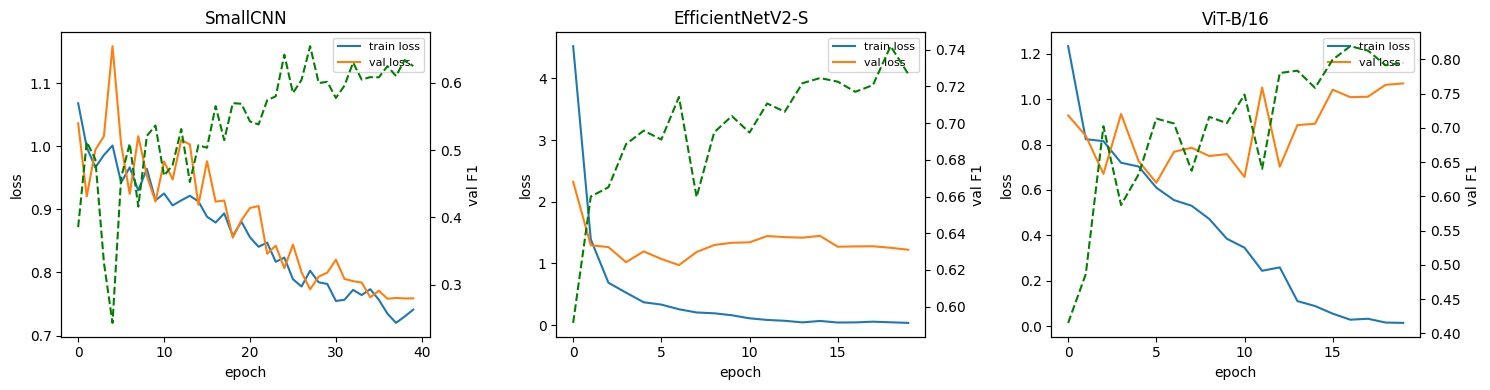

In [11]:
import matplotlib.pyplot as plt
# (a) training curves
fig, axes = plt.subplots(1, len(trained), figsize=(5*len(trained), 4), squeeze=False)
for ax,(name,obj) in zip(axes[0], trained.items()):
    h = obj["hist"]
    ax.plot(h["train_loss"], label="train loss")
    ax.plot(h["val_loss"], label="val loss")
    ax2 = ax.twinx(); ax2.plot(h["val_f1"], "--", color="green", label="val macro-F1")
    ax.set_title(name); ax.set_xlabel("epoch"); ax.set_ylabel("loss"); ax2.set_ylabel("val F1")
    ax.legend(loc="upper right", fontsize=8)
plt.tight_layout(); plt.savefig(OUT/"figures"/"training_curves.png", dpi=120); plt.show()

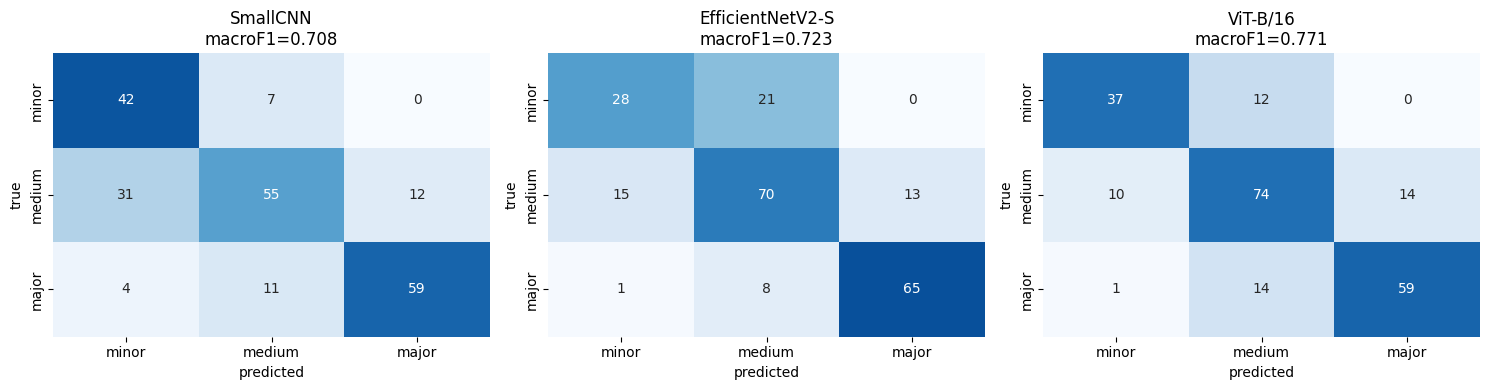

In [12]:
import seaborn as sns, numpy as np
# (b) confusion matrices (row-normalised)
fig, axes = plt.subplots(1, len(results), figsize=(5*len(results), 4), squeeze=False)
short = [c.split("_")[0] for c in CLASSES]
for ax,(name,r) in zip(axes[0], results.items()):
    cm = r["cm"].astype(float); cmn = cm / cm.sum(1, keepdims=True).clip(min=1)
    sns.heatmap(cmn, annot=cm.astype(int), fmt="d", cmap="Blues", vmin=0, vmax=1,
                xticklabels=short, yticklabels=short, ax=ax, cbar=False)
    ax.set_title(f"{name}\nmacroF1={r['macro_f1']:.3f}")
    ax.set_xlabel("predicted"); ax.set_ylabel("true")
plt.tight_layout(); plt.savefig(OUT/"figures"/"confusion_matrices.png", dpi=120); plt.show()

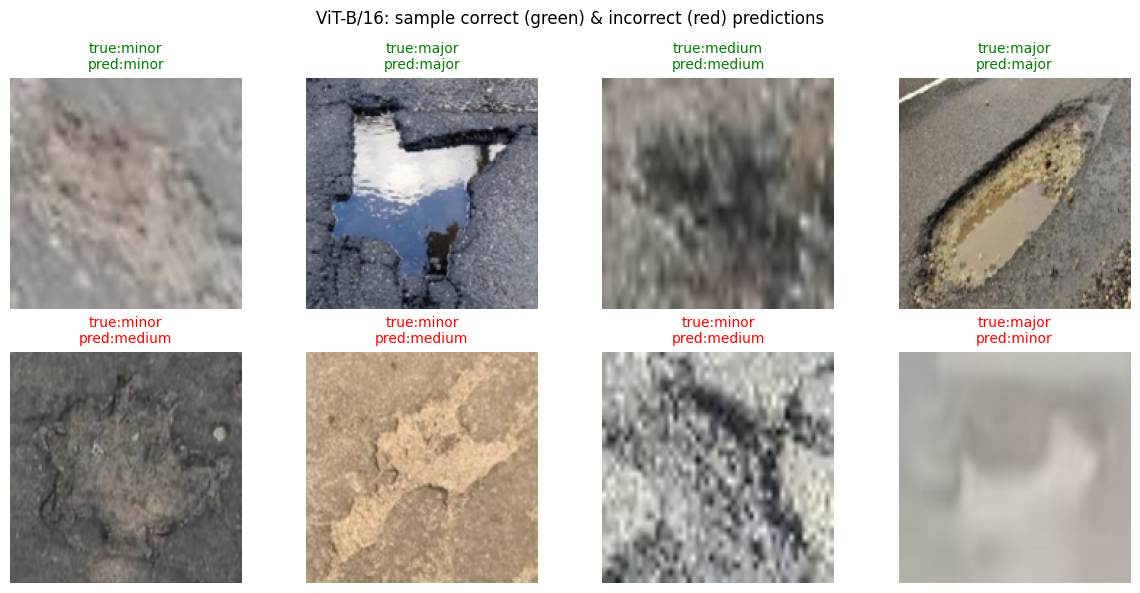

In [13]:
# (c) prediction gallery for the best model: correct (green) & incorrect (red)
import numpy as np, torch
from PIL import Image
name = best_model; r = results[name]
paths = [p for p,_ in test_ds.samples]
den = np.array(IMAGENET_STD); mn = np.array(IMAGENET_MEAN)
idx_correct = np.where(r["y"]==r["p"])[0]; idx_wrong = np.where(r["y"]!=r["p"])[0]
sel = list(np.random.RandomState(SEED).permutation(idx_correct)[:4]) + \
      list(np.random.RandomState(SEED).permutation(idx_wrong)[:4])
fig, axes = plt.subplots(2, 4, figsize=(12,6))
for ax, i in zip(axes.ravel(), sel):
    ax.imshow(Image.open(paths[i]).resize((160,160))); ax.axis("off")
    t, pr = CLASSES[r["y"][i]].split("_")[0], CLASSES[r["p"][i]].split("_")[0]
    ok = r["y"][i]==r["p"][i]
    ax.set_title(f"true:{t}\npred:{pr}", color=("green" if ok else "red"), fontsize=10)
plt.suptitle(f"{name}: sample correct (green) & incorrect (red) predictions")
plt.tight_layout(); plt.savefig(OUT/"figures"/"prediction_gallery.png", dpi=120); plt.show()

## 7. Save all metrics for the report

In [14]:
import json, numpy as np
export = {"seed":SEED, "img_size":IMG_SIZE, "device":str(DEVICE),
          "model_cfgs":{k:{kk:vv for kk,vv in v.items()} for k,v in MODEL_CFGS.items()},
          "class_weights":dict(zip(CLASSES, [round(float(w),4) for w in class_weights.cpu()])),
          "results":{}}
for name, r in results.items():
    export["results"][name] = dict(accuracy=float(r["accuracy"]), macro_f1=float(r["macro_f1"]),
        per_class=r["per_class"], confusion_matrix=r["cm"].tolist())
export["best_model"] = best_model
(OUT/"metrics.json").write_text(json.dumps(export, indent=2))
print("Saved:", OUT/"metrics.json")
print("Figures + weights + comparison table are in", OUT)

Saved: /kaggle/working/models_out/metrics.json
Figures + weights + comparison table are in /kaggle/working/models_out


## Done — Phase 2/3 outputs (in `models_out/`)

- `weights/*.pt` — best checkpoint per model
- `model_comparison.csv` — the headline table (accuracy, macro-F1, per-class F1)
- `metrics.json` — full metrics incl. confusion matrices, for the report
- `figures/` — training curves, confusion matrices, prediction gallery

**Next (Phase 4/5):** we turn these figures + `metrics.json` into the results & discussion
sections of the report — the error analysis (which severities get confused and why), the effect
of the class imbalance, and the recommended model.
